# Multi-class Classification and Model Selection

A companion to the handout of the same name. The setup cell below writes the two data files, so
nothing has to be downloaded first, and the cells run in order from the top.

`train.csv` holds 3660 customer records, 915 of each of the four tiers `bronze`, `silver`, `gold`
and `platinum`, with four numeric columns (`age`, `income`, `tenure_months`, `score`), three
categorical ones (`region`, `plan`, `channel`), the tier and a `churn` label. `audit_log.csv` holds
the true and the predicted tier of 1200 rows from another classifier. The data is synthetic and
seeded, so every number below is reproducible. Some cells train many networks: the regularisation
and model-selection sections take a few minutes on a CPU.

In [ ]:
#@title Setup: write train.csv and audit_log.csv  { display-mode: "form" }
# Writes the files every cell below reads: the 3640 customer records and the 1200 rows of a classifier's log.
import base64, gzip, os

_FILES = {
    "train.csv": (
        "..."
    ),
    "audit_log.csv": (
        "H4sIAAAAAAAC/81bSXIiQQy88xY+5TGETQReAuM5zOsnbLw2WjJTEvYJmqaqq1RSSkqpj4fn4+368bDd7K6P283qz+Hh/t92ffpY"
        "Pe32f7eH9ekjvLp52G/ev7/N8fLT6nF/ddzdP9+drr7PHl19jDOfFo18+6e5g9dVGutKx5hP+pzNe0q0zq8SSyVrzOav0r8TrjiS"
        "Lb+WUC7p8/x5gVG4PkRaRWr7Um+N/UMaTq96Oc9CymfyxiXwfS/eqRpaDZwlcM94FiNP3yLwq8TeUUwTrWfxzZzTxxRfRyFt8lEy"
        "kU2E+LHO46vEMaPnynye4TkSFA4xkUdtdd+RBvVICNMUH5VSv+lLo+BDVY3jz8r7V4+Ei7gb3fOla/ot324iZInuobEZGivNaz+m"
        "e/ieySgl+p+Dypj1xaNyvAN2TCEpLSU+jk1XavnunrOMvGocDzJ5lWZdnobzuEhjnBbDlSJ8PDI39OzM79U9U6s841wcsHuSMTBi"
        "KNVDxVbA3E11xIvJ02wGeC6KGdE9jNMAVhTpgRlFGne+arufq5oSTDClGBF5sy/weyKaYqQeoiuNAeoVrYNiFoTjOprf4p5TZXJQ"
        "zkrJcRiOlJRdwDFQXolkdjEM9TH4h/xkQRp4pN+TnaIxyVJ/8BykuBYgV+SZFI+tVDEOXR2KQ5h372YG1JyiJ3LswEJUL3rsqif6"
        "rCP9BL8zsRuW71L0W8vs6RmTOFRdL4ZE/b6qfqJZJUmr4vXoZFF6xUiZ0PoCHz2PRQorw9UX2ZkmuA2bx8t+ZXNBFGEQVlGzYyMC"
        "ErLP32St8zFQnZesV9BL1lvwMt4YKK9srbYqqKSc8UCfC60TRB5A83+sX8c59YgDR+q7vuQ7elOoHArB9CZ7zT1cWldttSyV95ar"
        "+3Rlq163V7lJXyt9b8z305U9MdwzpPAKarfmPEPnyzfkx3HvRvlLrYOgNRMBenkwVr0axaP1GfJ0Equqe9h6zwZ9NdivVuc7J/i/"
        "IBbA4rGkM+7MW6eMjsbvXLqiVuUXMF+m9VqXOLYe7SrooZrXMV0PWIVCidz9+vlEr8w8N4VqI64TPdmp15tCdvtcrMdQq5HgPT9I"
        "9KX1T1ferpmQnfZuQ3cswUqCP5FuxvVsBZOygLJZBrENHGq0Y/R9OOVMKK4s6SJq6dzB+8BJFg3mUoDTKvnRQuUW7bZVMA7dU2+/"
        "gtKDofFMl+0IQjP8/rfMJvaWW5JS7fRlhEe6Jh7WVuSPJkZ4/kx5m2MEKZreMrDmUt76Q7h1X1/+A7QH/vmGPgAA"
    ),
}

for _name, _blob in _FILES.items():
    if not os.path.exists(_name):
        with open(_name, "wb") as f:
            f.write(gzip.decompress(base64.b64decode(_blob)))
    print(_name, os.path.getsize(_name) // 1024, "KB")

train.csv 180 KB
audit_log.csv 15 KB


### The rows and the feature matrix

`train` holds the rows of the file as dictionaries, as `csv.DictReader` returns them.
`features(rows, fit)` returns the feature matrix of `rows` as a NumPy array of 17 columns: the four
numeric columns with their gaps filled with the medians of the rows `fit` and standardised with the
means and standard deviations of those rows, then one 0/1 column per region, plan and channel.

In [ ]:
import copy, csv, itertools
import numpy as np
import torch
import torch.nn as nn

with open("train.csv", newline="", encoding="utf-8") as f:
    train = list(csv.DictReader(f))

NUMERIC = ["age", "income", "tenure_months", "score"]
CATEGORIES = {"region": ["North", "Harbour", "Midland", "Eastfield", "Southgate", "Upland"],
              "plan": ["basic", "standard", "premium", "legacy"],
              "channel": ["shop", "phone", "online"]}

def column(rows, name):
    return np.array([float(r[name]) if r[name] != "" else np.nan for r in rows])

def features(rows, fit):
    """The 17 feature columns of rows, with every statistic taken from the rows fit."""
    med = {c: np.nanmedian(column(fit, c)) for c in NUMERIC}
    def num(rs):
        return np.stack([np.where(np.isnan(column(rs, c)), med[c], column(rs, c)) for c in NUMERIC],
                        axis=1)
    mean, std = num(fit).mean(axis=0), num(fit).std(axis=0)
    blocks = [(num(rows) - mean) / std]
    for cat, names in CATEGORIES.items():
        v = np.array([r[cat] for r in rows])
        blocks.append(np.stack([(v == n).astype(float) for n in names], axis=1))
    return np.concatenate(blocks, axis=1)

print(len(train), "rows;", features(train[:5], train).shape)

3660 rows; (5, 17)


## 01 Multi-class classification

One logit per class, an integer label, and a loss that applies the softmax itself.

In [ ]:
TIERS = ["bronze", "silver", "gold", "platinum"]

rng = np.random.default_rng(42)
idx = rng.permutation(len(train))               # 0 to 3659 in a random order
parts = np.split(idx, [732, 1464])              # the first 732, the next 732, the rest
test_rows, val_rows, fit_rows = ([train[i] for i in part] for part in parts)

def tensors(rows):
    x = torch.tensor(features(rows, fit_rows), dtype=torch.float32)     # (n, 17)
    y = torch.tensor([TIERS.index(r["tier"]) for r in rows])            # (n,) int64
    return x, y

(xf, yf), (xv, yv), (xt, yt) = tensors(fit_rows), tensors(val_rows), tensors(test_rows)
print((len(yf), len(yv), len(yt)))       # -> (2196, 732, 732)
print(torch.bincount(yf))       # -> tensor([540, 570, 538, 548])   fitting rows per tier

(2196, 732, 732)
tensor([540, 570, 538, 548])


One permutation of the 3660 rows gives 732 test rows, 732 validation rows and 2196 rows to fit on, and every split is encoded with the statistics of the fitting rows. The label of a row is the position of its tier in `TIERS`, an integer from 0 to 3. `torch.tensor` turns a list of Python integers into an int64 tensor, which PyTorch also calls `long`.

In [ ]:
class TierNet(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.stack = nn.Sequential(
            nn.Linear(n_in, 48), nn.ReLU(),
            nn.Linear(48, 24), nn.ReLU(),
            nn.Linear(24, 4))               # FOUR logits, no softmax here

    def forward(self, x):
        return self.stack(x)                # (n, 17) -> (n, 4), no squeeze

loss_fn = nn.CrossEntropyLoss()             # logits and integer labels

The last layer has one unit *per class*. There is no `squeeze`, because the output has one row of four scores per input row. The label is a **long** holding the class index, not a float and not a one-hot row; a float label raises an error:

In [ ]:
logits = torch.tensor([[2.0, 1.0, 0.1, 0.0]])       # (1, 4): one row, four logits
try:
    nn.CrossEntropyLoss()(logits, torch.tensor([0.0]))
except RuntimeError as e:
    print("RuntimeError:", e)
# RuntimeError: expected target dtype to be Long or Byte, but got Float

RuntimeError: expected scalar type Long but found Float


### CrossEntropyLoss internals

In [ ]:
y = torch.tensor([0])                                       # the true class is 0
print(nn.CrossEntropyLoss()(logits, y).item())              # -> 0.502461
print(nn.NLLLoss()(torch.log_softmax(logits, dim=1), y).item())    # -> 0.502461   the same thing

0.5024607181549072
0.5024607181549072


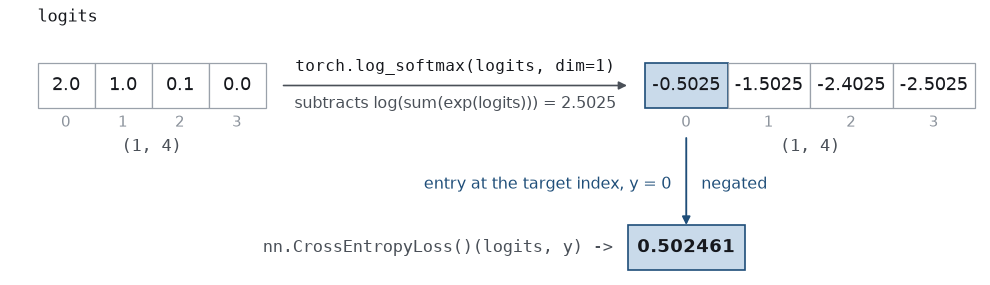

CrossEntropyLoss on the logits above: log_softmax subtracts 2.5025 from every logit, and the loss is the entry at the target index y = 0, negated: 0.502461.

`torch.log_softmax(z, dim=1)` subtracts `log(sum(exp(z)))` from every logit of a row, which gives the logarithms of the softmax probabilities, and `nn.NLLLoss` takes the entry at the target index and negates it. The loss of a row is therefore minus the log of the probability given to its true class. `CrossEntropyLoss` applies the two in one class for numerical stability, as `BCEWithLogitsLoss` combines the sigmoid and the binary cross-entropy. A softmax applied before it is therefore applied twice:

In [ ]:
print(nn.CrossEntropyLoss()(torch.softmax(logits, dim=1), y).item())  # -> 1.055218   no error

1.0552181005477905


No error or warning is raised, and the model is trained on a different loss.

### argmax and the starting loss

In [ ]:
print(torch.softmax(logits, dim=1))     # -> tensor([[0.6050, 0.2226, 0.0905, 0.0819]])

torch.manual_seed(42)
net = TierNet(17)
print(loss_fn(net(xf), yf).item())      # -> 1.3975   untrained; ln 4 = 1.3863

tensor([[0.6050, 0.2226, 0.0905, 0.0819]])
1.3975327014923096


Softmax is needed only for the probabilities themselves; it is increasing, so `argmax` of the logits and `argmax` of the softmax are the same class. On `C` balanced classes an untrained model should start near `ln C`, the loss of giving every class the probability `1 / C`: this one starts at 1.3975 against `ln 4 = 1.3863`.

### Training on the tiers

In [ ]:
def train_epochs(net, opt, epochs):
    history = []
    for epoch in range(epochs):
        net.train()
        perm = torch.randperm(len(xf))
        losses = []
        for i in range(0, len(xf), 128):
            b = perm[i:i + 128]
            opt.zero_grad()
            loss = loss_fn(net(xf[b]), yf[b])
            loss.backward()
            opt.step()
            losses.append(loss.item())
        net.eval()
        with torch.no_grad():
            history.append((np.mean(losses), loss_fn(net(xv), yv).item()))
    return np.array(history)                # (epochs, 2): training and validation loss

opt = torch.optim.Adam(net.parameters(), lr=1e-3)
history = train_epochs(net, opt, 40)
with torch.no_grad():
    pred = net(xv).argmax(dim=1)        # (732, 4) -> (732,) the index of the largest logit
print((pred == yv).float().mean().item())      # -> 0.5574   validation accuracy

0.5573770403862


`train_epochs` runs the minibatch loop over the fitting rows for a number of epochs and records, for every epoch, the mean loss of its batches and the loss on the validation rows. `net.train()` and `net.eval()` switch layers such as dropout between their training and their prediction behaviour. After 40 epochs the network predicts the tier of 0.557 of the validation rows, against 0.25 for a constant answer or a random guess.

### Output layer, loss and label dtype

The output layer of a network together with the loss that goes with it is its **head**. A network that predicts an amount, one that predicts a yes-or-no label and this one differ only in the head, the dtype of the target, and how the output is read as a prediction. The output for an amount has no activation, since a sigmoid would restrict it to the range 0 to 1, and `MSELoss` squares each difference, so an error of 10 adds a hundred times as much to the loss as an error of 1. `BCEWithLogitsLoss` takes one logit per row and a float label of 0.0 or 1.0; `CrossEntropyLoss` takes one logit per class and the class index as a long.

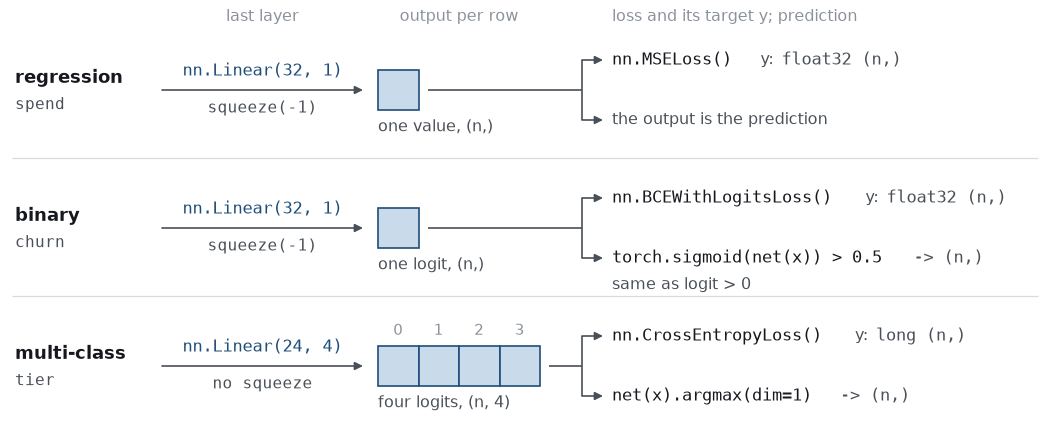

The three heads. Each lane shows the last layer, the output for one row, the loss with the dtype and shape of its target, and how the output is read as a prediction.

**Try it.** Train a new `TierNet(17)` for 40 epochs with `lr=1e-2` and compare its validation accuracy with the 0.557 above.

## 02 Per-class metrics

The 1200 rows of `audit_log.csv` hold the true and the predicted tier of each row, from a classifier that is 78.5 per cent accurate and never predicts one of the four classes.

In [ ]:
with open("audit_log.csv", newline="") as f:
    log = list(csv.DictReader(f))       # 1200 rows: the true and the predicted tier
truth = np.array([TIERS.index(r["truth"]) for r in log])      # (1200,) true class
pred = np.array([TIERS.index(r["predicted"]) for r in log])   # (1200,) predicted class

print((truth == pred).mean())   # -> 0.785

print(np.bincount(truth, minlength=4)) # -> [387 509 239  65]   count per true class
print(np.bincount(pred, minlength=4))  # -> [404 565 231   0]   count per predicted class

0.785
[387 509 239  65]
[404 565 231   0]


The last entries differ: none of the 65 platinum rows is predicted as platinum. Platinum is 5.4 per cent of the rows, so missing all of them lowers the accuracy by only 5.4 points, and the accuracy alone does not reveal it.

### Precision, recall and F1

For one class `c`, here gold, the predictions are counted against the truth:

In [ ]:
c = TIERS.index("gold")                          # 2
tp = int(((pred == c) & (truth == c)).sum())     # predicted c, and really c
fp = int(((pred == c) & (truth != c)).sum())     # predicted c, but not c
fn = int(((pred != c) & (truth == c)).sum())     # really c, but predicted otherwise

precision = tp / (tp + fp) if tp + fp else 0.0   # of those called c, how many were
recall    = tp / (tp + fn) if tp + fn else 0.0   # of the real c, how many were found
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
print((tp, fp, fn))                              # -> (147, 84, 92)
print((round(precision, 3), round(recall, 3), round(f1, 3)))          # -> (0.636, 0.615, 0.626)

(147, 84, 92)
(0.636, 0.615, 0.626)


**Precision** is the share of correct predictions among the rows predicted as the class. **Recall** is the share of the rows of the class that were predicted as it. F1 is their harmonic mean, which is low whenever either is low. The conditional expressions guard the divisions: a class that is never predicted has `tp + fp == 0`.

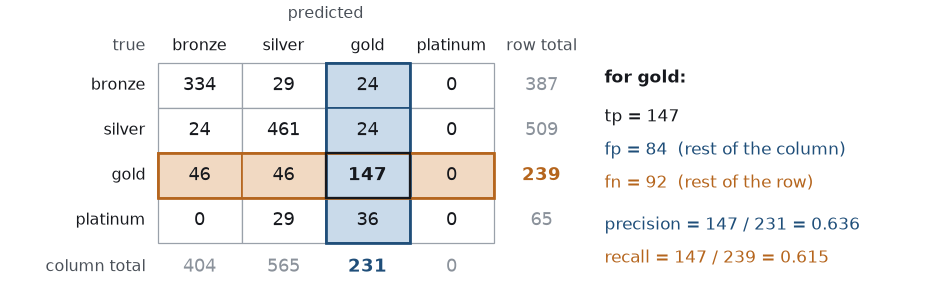

The 1200 rows counted by true class (rows) and predicted class (columns). For gold, precision divides tp = 147 by the column total 231, and recall divides it by the row total 239.

| class | n | tp | fp | fn | precision | recall | F1 |
|---|---|---|---|---|---|---|---|
| bronze | 387 | 334 | 70 | 53 | 0.827 | 0.863 | 0.845 |
| silver | 509 | 461 | 104 | 48 | 0.816 | 0.906 | 0.858 |
| gold | 239 | 147 | 84 | 92 | 0.636 | 0.615 | 0.626 |
| platinum | 65 | 0 | 0 | 65 | 0.000 | 0.000 | 0.000 |

Bronze and silver reach an F1 of 0.84 and 0.86, gold 0.63, and platinum 0, because the model never predicts it. The accuracy of 78.5 per cent does not show these differences.

### Class imbalance

The loss is averaged over rows, so a class with 5.4 per cent of the rows contributes 5.4 per cent of the terms in that average. Predicting only the common classes keeps the average loss low and gets every row of the rare class wrong. The usual responses are to weight the loss by inverse class frequency (`nn.CrossEntropyLoss(weight=...)`), to resample the training set towards balance, or to accept it and report the per-class numbers beside the 78.5.

`np.bincount(pred)` next to an accuracy shows any class that is predicted rarely or never, and so also shows when a binary classifier predicts one class for every row.

**Try it.** Compute precision, recall and F1 for all four classes in one loop over `range(4)`, and compare them with the table.

## 03 Feature scaling

The same gradient descent on the same two columns, run twice: once on the raw values and once on standardised ones.

`income` spans 6139 to 142611 and `tenure_months` spans 0 to 145. Their standard deviations are 14701 and 19.3, a ratio of about 760. Logistic regression of `churn` on the two columns, by plain gradient descent on all 3660 rows from zero weights, 400 steps at a learning rate of 0.05, is the same in both runs apart from one line, `x = (x - x.mean(axis=0)) / x.std(axis=0)`, which standardises the columns of the second run. The loss is the mean binary cross entropy with 1e-12 added inside each logarithm, `-mean(y * log(p + 1e-12) + (1 - y) * log(1 - p + 1e-12))`:

| step | unscaled loss | standardised loss |
|---|---|---|
| 0 | 0.693 | 0.693 |
| 5 | 17.175 | 0.684 |
| 10 | 10.456 | 0.677 |
| 20 | 10.456 | 0.664 |
| 40 | 17.175 | 0.647 |
| 80 | 10.456 | 0.630 |
| 140 | 10.456 | 0.620 |
| 220 | 10.456 | 0.617 |
| 310 | 10.456 | 0.616 |
| 399 | 17.175 | 0.616 |

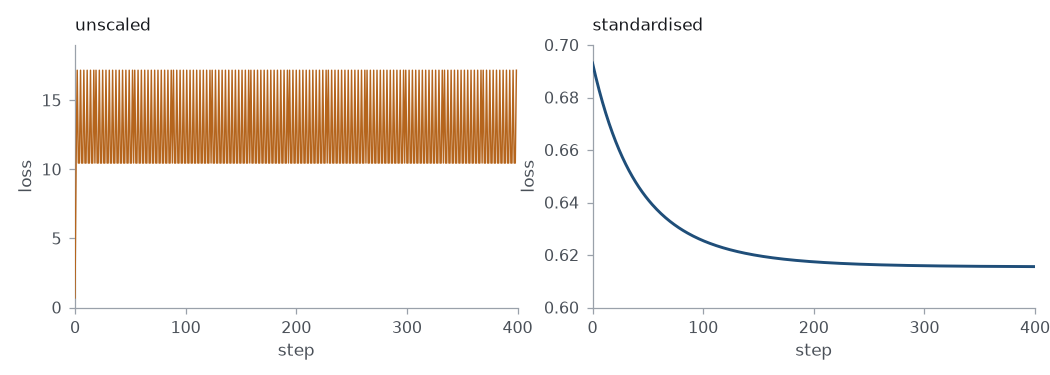

The loss at each of the 400 steps, each panel on its own y axis. From step 5 on the unscaled loss takes only two values, 10.456 and 17.175.

Both start at 0.693, which is `ln 2`, the loss of a model that predicts a probability of 0.5 for every row. The standardised run then descends smoothly to 0.616 and stays there. The unscaled run reaches 17.175 by step 5, and from then on takes only the values 17.175 and 10.456 for the remaining 395 steps.

The two values are the losses of a model that is certain about every row. From step 5 on, every probability is within 1e-12 of 0 or of 1, and a row whose true label gets the probability 0 adds `-log(1e-12) = 27.631` to the sum. At 17.175 every customer is predicted to churn, and the 2275 who stayed add 27.631 each: 27.631 × 2275 / 3660 = 17.175. At 10.456 no customer is predicted to churn, and the 1385 who left add it: 27.631 × 1385 / 3660 = 10.456.

### Gradient scale and learning rate

One learning rate is applied to every parameter. At the first step the gradient with respect to the income weight is 4880.1 and the one for the tenure weight 5.75, about 850 times smaller, because the input the income weight multiplies is about 760 times larger. A step small enough to be stable for income is so small for tenure that the tenure weight barely changes; a step large enough for tenure overshoots on income, lands further from the minimum than it started, and overshoots back, which produces the oscillation in the table.

Standardising gives every column mean 0 and standard deviation 1, so the gradients of the two weights are of similar size and one learning rate suits both.

## 04 Optimizers

An optimizer turns the gradients that `backward()` stores in `.grad` into a change of every parameter. Plain gradient descent subtracts the learning rate times the gradient; momentum also reuses the steps before, and Adam divides each parameter's step by the size of its recent gradients.

In [ ]:
def after_steps(make_opt, grad, steps=3):
    p = torch.zeros(2, requires_grad=True)
    opt = make_opt([p])
    out = []
    for step in range(steps):
        p.grad = grad.clone()               # in place of loss.backward()
        opt.step()
        out.append(p.tolist())
    return out                              # the parameter after every step

g = torch.tensor([1.0, 0.01])               # two parameters, gradients 100 times apart
print(after_steps(lambda ps: torch.optim.SGD(ps, lr=0.1), g))
# -> [[-0.1, -0.001], [-0.2, -0.002], [-0.3, -0.003]]
print(after_steps(lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9), g))
# -> [[-0.1, -0.001], [-0.29, -0.0029], [-0.561, -0.00561]]
print(after_steps(lambda ps: torch.optim.Adam(ps, lr=0.1), g))
# -> [[-0.1, -0.1], [-0.2, -0.2], [-0.3, -0.3]]

[[-0.10000000149011612, -0.0010000000474974513], [-0.20000000298023224, -0.0020000000949949026], [-0.30000001192092896, -0.003000000026077032]]
[[-0.10000000149011612, -0.0010000000474974513], [-0.28999999165534973, -0.002899999963119626], [-0.5609999895095825, -0.005609999876469374]]
[[-0.09999998658895493, -0.09999989718198776], [-0.19999998807907104, -0.19999980926513672], [-0.29999998211860657, -0.2999997138977051]]


`after_steps` sets `p.grad` by hand to the same gradient at every step, so that only the update rule differs between the three runs. Each optimizer applies its rule to every parameter separately; with `g` the gradient, `lr` the learning rate and `t` the number of the step:

| optimizer | update at every step |
|---|---|
| `SGD(lr)` | `p -= lr * g` |
| `SGD(lr, momentum=0.9)` | `b = 0.9 * b + g (b = g at the first step)`<br>`p -= lr * b` |
| `Adam(lr)` | `m = 0.9 * m + 0.1 * g`<br>`v = 0.999 * v + 0.001 * g ** 2`<br>`m_hat = m / (1 - 0.9 ** t)`<br>`v_hat = v / (1 - 0.999 ** t)`<br>`p -= lr * m_hat / (v_hat ** 0.5 + 1e-8)` |

Plain SGD moves each parameter in proportion to its gradient: 0.1 and 0.001 per step. The momentum buffer `b` of the first parameter, whose gradient is 1.0 at every step, grows from step to step:

```
step 1: b  =  1.0                       p = 0 - 0.1 × 1.0 = -0.1
step 2: b  =  0.9 × 1.0 + 1.0 = 1.9     p = -0.1 - 0.1 × 1.9 = -0.29
step 3: b  =  0.9 × 1.9 + 1.0 = 2.71    p = -0.29 - 0.1 × 2.71 = -0.561
```

Under a gradient that keeps its sign, `b` grows towards `g / (1 - 0.9) = 10 * g`, so the step grows towards ten times the plain one. A gradient that changes sign from step to step partly cancels in `b`. Adam's `m` is a running average of the gradient and `v` of its square; the divisions by `1 - 0.9 ** t` and `1 - 0.999 ** t` correct the bias of averages that start at 0. For the second parameter at the first step:

```
m_hat  =  (0.1 × 0.01) / (1 - 0.9) = 0.01              the gradient
v_hat  =  (0.001 × 0.0001) / (1 - 0.999) = 0.0001      the square of the gradient
 step  =  0.1 × 0.01 / (0.0001 ** 0.5 + 1e-8) = 0.1    lr × g / |g|
```

Under a constant gradient, `m_hat` is the gradient and `v_hat ** 0.5` its size, and their ratio is 1 or -1: every parameter moves by the learning rate per step, whatever the size of its gradient. The two parameters, with gradients 100 times apart, both move by 0.1.

### Paths on an elongated loss

In [ ]:
def bowl(w):                                    # its minimum is 0, at w = (0, 0)
    return 0.5 * (w[0] ** 2 + 25 * w[1] ** 2)   # 25 times as curved along w[1]

def path(make_opt, steps=40):
    w = torch.tensor([-4.0, 1.0], requires_grad=True)
    opt = make_opt([w])
    points = [w.detach().clone()]
    for step in range(steps):
        opt.zero_grad()
        bowl(w).backward()
        opt.step()
        points.append(w.detach().clone())
    return torch.stack(points)                  # (41, 2): the start and every step

paths = {"SGD": path(lambda ps: torch.optim.SGD(ps, lr=0.02)),
         "momentum": path(lambda ps: torch.optim.SGD(ps, lr=0.02, momentum=0.9)),
         "Adam": path(lambda ps: torch.optim.Adam(ps, lr=0.2))}
print({name: round(bowl(p[-1]).item(), 3) for name, p in paths.items()})
# -> {'SGD': 1.589, 'momentum': 0.022, 'Adam': 0.171}

{'SGD': 1.589, 'momentum': 0.022, 'Adam': 0.171}


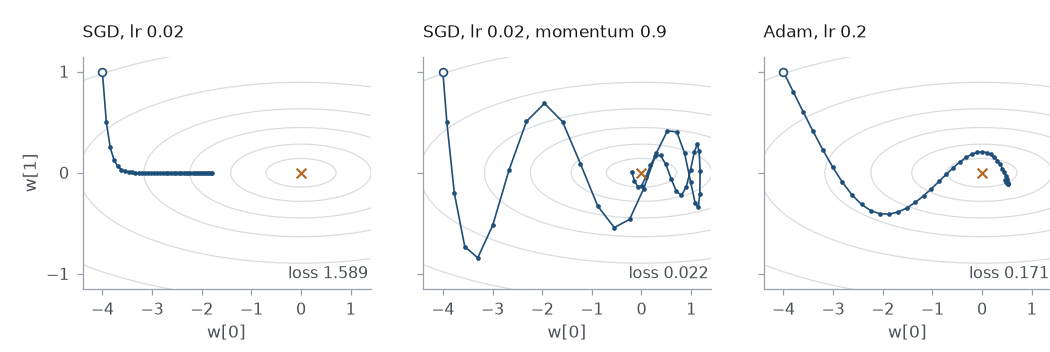

The 40 steps of each optimizer from w = (-4, 1), the open circle, on the contour lines of bowl, with w[1] drawn at about twice the scale of w[0]. The cross marks the minimum, and each panel gives the loss after the last step.

The loss is a long valley, 25 times as curved across as along, the shape the loss takes on two features of different scales. A step of plain gradient descent multiplies the distance to the minimum along `w[1]` by `1 - 0.02 × 25 = 0.5` and along `w[0]` by `1 - 0.02 × 1 = 0.98`: the path reaches the floor of the valley in a few steps and then moves along it by 2 per cent of the remaining distance per step, and after 40 steps the loss is still 1.589. A learning rate above `2 / 25 = 0.08` would make the steps across the valley grow instead of shrink. With momentum the steps along the valley add up, and after swings across the valley that the changing sign of the gradient there damps, the loss is 0.022. Adam moves both coordinates by about its learning rate at first, along the diagonal, and ends at 0.171.

### Optimizers on the tiers

In [ ]:
runs = {"SGD": lambda ps: torch.optim.SGD(ps, lr=0.01),
        "momentum": lambda ps: torch.optim.SGD(ps, lr=0.01, momentum=0.9),
        "Adam": lambda ps: torch.optim.Adam(ps, lr=0.001)}
curves = {}
for name, make in runs.items():
    torch.manual_seed(42)
    net = TierNet(17)
    curves[name] = h = train_epochs(net, make(net.parameters()), 100)
    best = h[:, 1].argmin()
    print(f"{name:<9} training {h[9, 0]:.3f} {h[99, 0]:.3f}   "
          f"validation best {h[best, 1]:.3f} at epoch {best + 1}, last {h[99, 1]:.3f}")
# SGD       training 1.375 0.939   validation best 0.934 at epoch 100, last 0.934
# momentum  training 0.955 0.883   validation best 0.926 at epoch 26, last 0.936
# Adam      training 0.935 0.843   validation best 0.926 at epoch 12, last 0.958

SGD       training 1.375 0.939   validation best 0.934 at epoch 100, last 0.934
momentum  training 0.955 0.883   validation best 0.926 at epoch 26, last 0.936
Adam      training 0.935 0.843   validation best 0.926 at epoch 12, last 0.958


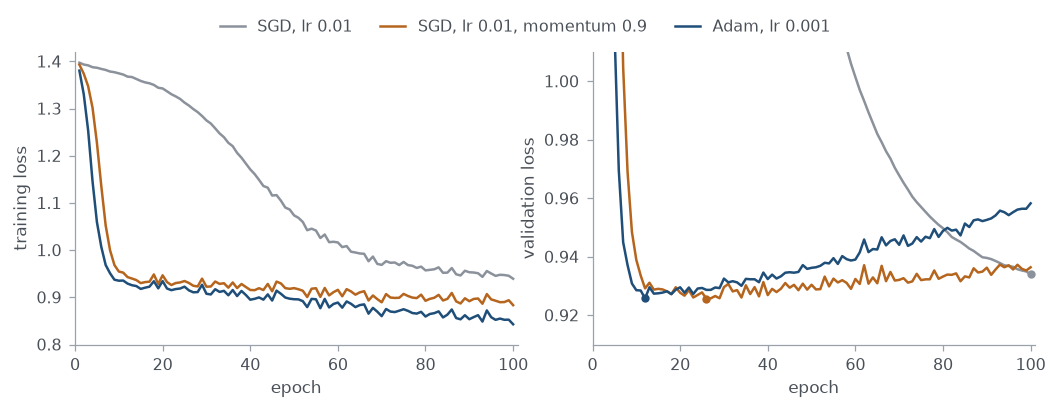

The training loss (left) and the validation loss (right) of TierNet at every epoch of the three runs above, all from the same initial weights. The dots mark the lowest validation loss of each run. The right panel stops at 1.01; the validation loss of SGD comes below it at epoch 59, of momentum at epoch 7 and of Adam at epoch 6.

Momentum at the same learning rate brings the training loss to 0.955 in 10 epochs, where plain SGD needs 84, and Adam at 0.001 reaches 0.935 in 10 epochs, which plain SGD does not reach in 100. The lowest validation losses are close together, 0.934 for SGD and 0.926 for momentum and for Adam, but they come at epochs 100, 26 and 12. After their minimum the validation losses of momentum and Adam rise, to 0.936 and 0.958 at epoch 100, while their training losses keep falling, to 0.883 and 0.843: the faster optimizers start to overfit sooner, and plain SGD is still improving at epoch 100.

### Adam on unscaled features

Adam does not remove the need to scale the features. Logistic regression on the unscaled `income` and `tenure_months`, as `nn.Linear(2, 1)` from zero weights with `BCEWithLogitsLoss` on all 3640 rows, has first gradients of 4880.1 for the income weight and 5.75 for the tenure weight, and Adam at a learning rate of 0.05 moves both weights by 0.05 in its first step. A change of 0.05 in the income weight changes the logit of a customer with the mean income, 31060, by 1553, so the probabilities swing between 0 and 1: after step 5 the loss does not fall below 1.3 in 400 steps, and over the last 100 steps it stays above 4 and rises above 100. On the standardised columns the same optimizer settles at a loss of 0.615.

**Try it.** Run `path` with `torch.optim.SGD(ps, lr=0.09)`, above the limit of 0.08, and look at the last rows of the path.

## 05 Regularisation

A network with many more parameters than the training rows can pin down fits those rows ever more closely while its validation loss rises. Weight decay and dropout limit how closely it can fit them.

In [ ]:
class Wide(nn.Module):
    def __init__(self, n_in, p=0.0):
        super().__init__()
        self.stack = nn.Sequential(
            nn.Linear(n_in, 256), nn.ReLU(), nn.Dropout(p),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(p),
            nn.Linear(128, 4))

    def forward(self, x):
        return self.stack(x)

def run(p=0.0, decay=0.0):
    torch.manual_seed(42)
    net = Wide(17, p)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=decay)
    return train_epochs(net, opt, 200)

def report(name, h):
    best = h[:, 1].argmin()
    print(f"{name:<18} training {h[-1, 0]:.3f}   validation best {h[best, 1]:.3f} "
          f"at epoch {best + 1}, last {h[-1, 1]:.3f}")

print(sum(q.numel() for q in Wide(17).parameters()))   # -> 38020
report("none", run())
# none               training 0.144   validation best 0.931 at epoch 10, last 2.228

38020
none               training 0.145   validation best 0.931 at epoch 10, last 2.210


`Wide` has 38020 parameters for 2196 fitting rows. Trained for 200 epochs with Adam at 0.001, its training loss falls to 0.144, while its validation loss is lowest at epoch 10, 0.931, and rises to 2.228 by epoch 200: the network fits the fitting rows ever more closely and the validation rows ever worse, which is **overfitting**. `nn.Dropout(p)` with `p = 0.0` passes its input through unchanged, so the same class serves the runs with and without dropout.

### Weight decay

In [ ]:
p = torch.tensor([1.0, -2.0], requires_grad=True)
opt = torch.optim.SGD([p], lr=0.1, weight_decay=0.2)
p.grad = torch.zeros(2)                 # no gradient from the loss at all
opt.step()
print(p.tolist())                       # -> [0.98, -1.96]   each times 1 - 0.1 * 0.2

[0.9800000190734863, -1.9600000381469727]


`weight_decay` adds `weight_decay` times each parameter to its gradient before the update, so that every step also moves every weight towards 0, in proportion to its size. With a gradient of 0, as above, one SGD step multiplies each weight by 1 - lr × weight_decay = 1 - 0.1 × 0.2 = 0.98. A weight stays away from 0 only where the gradient of the loss moves it away by as much as the decay moves it back. `Adam` adds the same term to the gradient before its division by the gradient size; `torch.optim.AdamW` instead subtracts `lr * weight_decay * p` from each weight directly, outside that division.

### Dropout

In [ ]:
drop = nn.Dropout(p=0.5)
torch.manual_seed(0)
print(drop(torch.ones(8)))  # -> tensor([0., 0., 2., 0., 0., 0., 2., 2.])   training mode
print(drop(torch.ones(8)))  # -> tensor([0., 2., 2., 2., 2., 0., 2., 2.])   a new pattern
drop.eval()
print(drop(torch.ones(8)))  # -> tensor([1., 1., 1., 1., 1., 1., 1., 1.])   evaluation mode

tensor([0., 0., 2., 0., 0., 0., 2., 2.])
tensor([0., 2., 2., 2., 2., 0., 2., 2.])
tensor([1., 1., 1., 1., 1., 1., 1., 1.])


`nn.Dropout(p)` sets each element of its input to 0 with probability `p`, drawing a new pattern on every call, and multiplies the other elements by `1 / (1 - p)`, here 2, so that the expected value of every element is unchanged. In evaluation mode it passes its input through unchanged. Placed after a hidden layer, it trains the next layer on a different random subset of about half of the units at every step. `net.train()` and `net.eval()` switch every dropout layer of a network between the two modes, which is why `train_epochs` calls them.

### Four runs of the wide network

In [ ]:
for name, kw in [("weight decay 0.001", dict(decay=1e-3)),
                 ("weight decay 0.01", dict(decay=1e-2)), ("dropout 0.5", dict(p=0.5))]:
    report(name, run(**kw))
# weight decay 0.001 training 0.355   validation best 0.930 at epoch 10, last 1.388
# weight decay 0.01  training 0.932   validation best 0.928 at epoch 44, last 0.936
# dropout 0.5        training 0.803   validation best 0.927 at epoch 14, last 1.020

weight decay 0.001 training 0.359   validation best 0.930 at epoch 10, last 1.394
weight decay 0.01  training 0.932   validation best 0.928 at epoch 44, last 0.936
dropout 0.5        training 0.797   validation best 0.927 at epoch 14, last 1.020


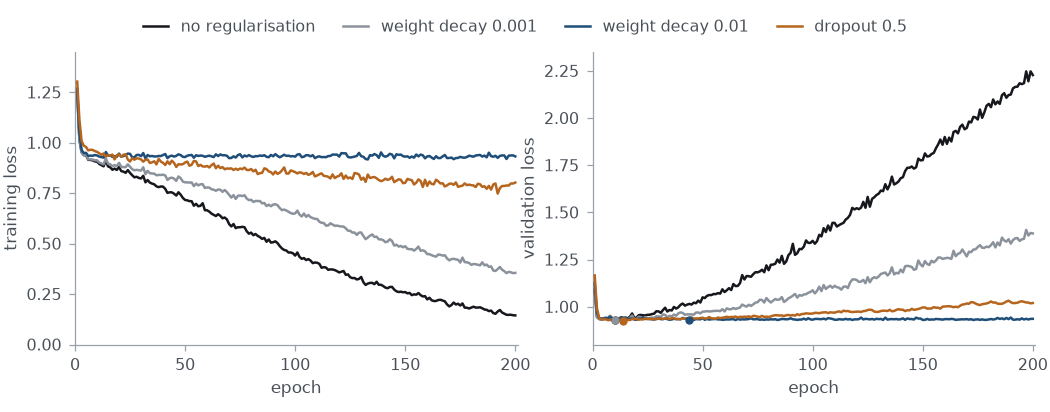

The training loss (left) and the validation loss (right) of Wide at every epoch of the four runs, all from the same initial weights. The training loss of the dropout run is the mean loss of its batches, computed with dropout active. The dots mark the lowest validation loss of each run.

Weight decay 0.01 holds the training loss at 0.932 after 200 epochs and the validation loss at 0.936, with its lowest value, 0.928, at epoch 44. Weight decay 0.001 and dropout 0.5 slow the rise of the validation loss without stopping it: at epoch 200 it is 1.388 and 1.020, against 2.228 without either. The lowest validation loss is about the same in all four runs, 0.927 to 0.931, so on this table neither method finds a better network than early stopping does; with weight decay 0.01 the validation loss depends far less on the epoch at which training stops, 0.940 at epoch 50 and 0.936 at epoch 200 against 1.050 and 2.228 without regularisation.

**Try it.** Train `Wide` with `run(p=0.5, decay=1e-2)`, dropout and weight decay together, and report it next to the four runs above.

## 06 Model selection

The depth, the width and the learning rate of a network are chosen by the loss on the validation rows, each candidate trained with early stopping. The test rows are used once, on the network chosen.

In [ ]:
def mlp(depth, width):
    layers, n = [], 17
    for _ in range(depth):
        layers += [nn.Linear(n, width), nn.ReLU()]
        n = width
    return nn.Sequential(*layers, nn.Linear(n, 4))

def best_of(net, opt, patience=20, max_epochs=200):
    best_loss, best_epoch, best_state = float("inf"), 0, None
    for epoch in range(max_epochs):
        val_loss = float(train_epochs(net, opt, 1)[0, 1])
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(net.state_dict())
        elif epoch - best_epoch >= patience:
            break
    net.load_state_dict(best_state)         # the weights of the best epoch
    return best_loss

`mlp(depth, width)` builds a network of `depth` hidden layers of `width` units each, with ReLU after each. `best_of` trains a network with early stopping on the validation loss and a patience of 20 epochs, restores the weights of its best epoch and returns that epoch's validation loss.

In [ ]:
results = []
for depth, width, lr in itertools.product([1, 2, 3], [16, 64, 256], [1e-3, 1e-2]):
    torch.manual_seed(42)
    net = mlp(depth, width)
    loss = best_of(net, torch.optim.Adam(net.parameters(), lr=lr))
    results.append((loss, depth, width, lr, net))
results.sort(key=lambda r: r[0])                # the lowest validation loss first
for loss, depth, width, lr, net in results[:4] + results[-2:]:
    print(f"depth {depth}   width {width:>3}   lr {lr:<5}   validation loss {loss:.4f}")
# depth 1   width  16   lr 0.01    validation loss 0.9218
# depth 1   width 256   lr 0.001   validation loss 0.9241
# depth 2   width  16   lr 0.01    validation loss 0.9261
# depth 1   width  64   lr 0.001   validation loss 0.9263
# depth 2   width 256   lr 0.01    validation loss 0.9428
# depth 3   width 256   lr 0.01    validation loss 0.9540

depth 1   width  16   lr 0.01    validation loss 0.9218
depth 1   width 256   lr 0.001   validation loss 0.9241
depth 2   width  16   lr 0.01    validation loss 0.9261
depth 1   width  64   lr 0.001   validation loss 0.9263
depth 2   width 256   lr 0.01    validation loss 0.9428
depth 3   width 256   lr 0.01    validation loss 0.9535


`itertools.product` runs through the 18 combinations of three depths, three widths and two learning rates, each trained with Adam from the same seed, and the loop prints the best four and the worst two. The networks with one hidden layer take four of the six best places, those with three hidden layers four of the six worst, and the three worst combine a learning rate of 0.01 with two or three hidden layers of 64 or 256 units. The best four lie between 0.9218 and 0.9263.

### Variation between seeds

In [ ]:
seed_losses = []
for seed in range(5):
    torch.manual_seed(seed)
    net = mlp(1, 16)
    seed_losses.append(best_of(net, torch.optim.Adam(net.parameters(), lr=1e-2)))
print((round(min(seed_losses), 4), round(max(seed_losses), 4)))      # -> (0.9235, 0.9260)

(0.9235, 0.926)


Trained from the seeds 0 to 4 instead of 42, the configuration with the lowest validation loss, one hidden layer of 16 units at a learning rate of 0.01, reaches validation losses from 0.9235 to 0.9260: every one of them above its 0.9218 from seed 42, and three of the five above the 0.9241 of the configuration ranked second. Its first place owes as much to the random initial weights and batches as to its depth, width and learning rate.

### The test rows

In [ ]:
loss, depth, width, lr, net = results[0]
with torch.no_grad():
    accuracy = (net(xt).argmax(dim=1) == yt).float().mean().item()
print(round(accuracy, 3))                       # -> 0.548   the test rows, used once

with torch.no_grad():
    accs = [(net(xt).argmax(dim=1) == yt).float().mean().item() for *_, net in results]
print((round(min(accs), 3), round(max(accs), 3)))        # -> (0.523, 0.560)   all 18

0.548
(0.523, 0.56)


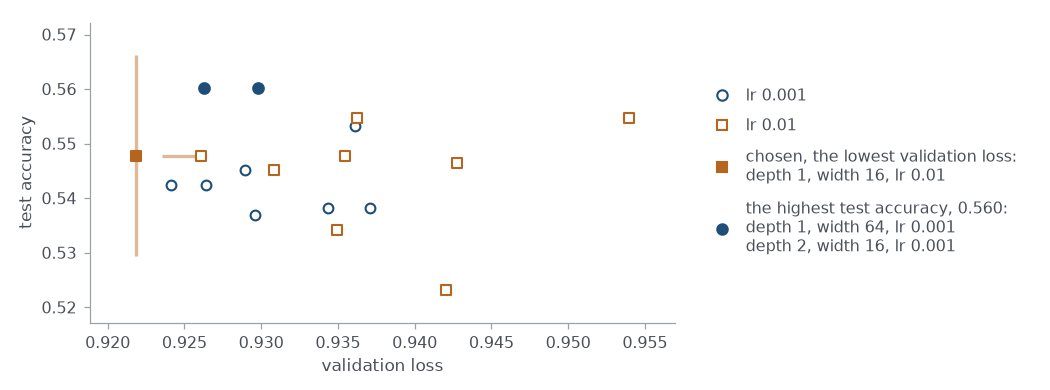

The 18 configurations by their validation loss and their accuracy on the test rows, circles for a learning rate of 0.001 and squares for 0.01. The horizontal bar spans the validation losses of the chosen configuration from the seeds 0 to 4, all to the right of its value from seed 42, and the vertical bar one standard error of its test accuracy on either side.

The chosen network predicts the tier of 0.548 of the test rows. The test accuracies of all 18 networks, computed here only to show what choosing by them would do, range from 0.523 to 0.560. The highest, 0.560, is reached by two configurations, ranked 4th and 8th by validation loss; chosen by its test accuracy, either would be reported at 0.560, the largest of 18 measurements that each carry noise, which tends to be higher than the accuracy the same network reaches on new rows. An accuracy near 0.55 on 732 rows has a standard error of `(0.55 * 0.45 / 732) ** 0.5 = 0.018`, so differences of one or two hundredths between these networks are within the noise of the measurement itself.

**Try it.** Add a learning rate of `1e-4` to the grid and see where those configurations rank.

### Further reading

- [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html), which documents the `weight` argument for class imbalance.
- [The loss functions](https://docs.pytorch.org/docs/stable/nn.html#loss-functions), for the ones beyond these three.
- [torch.optim](https://docs.pytorch.org/docs/stable/optim.html), with the update rule of every optimizer written out, among them `SGD`, `Adam` and `AdamW`.
- [nn.Dropout](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html).
- [Deep Learning](https://www.deeplearningbook.org/) by Goodfellow, Bengio and Courville, chapter 7 on regularisation and chapter 8 on optimization.